In [1]:
# Basic libraries
import os
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import nilearn.plotting as plotting  # Neuroimaging visualization

# Statistical analysis
import scipy.stats as stats
from scipy.stats import shapiro  # Normality check
from scipy.stats import mannwhitneyu  # Non-parametric test for un-normal distribution
from scipy.stats import ks_2samp  # Kolmogorov-Smirnov (K-S) Test
from scipy.stats import ttest_ind, spearmanr  # Other statistical tests

# Machine Learning
from sklearn.linear_model import LassoCV

# Neuroimaging utilities
import hcp_utils as hcp  # HCP dataset utility

# Pandas options
pd.options.mode.chained_assignment = None  # Hide long warnings

# Matplotlib inline for Jupyter notebooks
%matplotlib inline

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


### Load Data

Merged subject behavioral data from open access dataset and restricted datasets.

In [2]:
open_access_data = pd.read_csv("Behavioral Data/Behavioral_Data.csv")
open_access_data.head()

,Subject,Release,Acquisition,Gender,Age,3T_Full_MR_Compl,T1_Count,T2_Count,3T_RS-fMRI_Count,3T_RS-fMRI_PctCompl,...,Noise_Comp,Odor_Unadj,Odor_AgeAdj,PainIntens_RawScore,PainInterf_Tscore,Taste_Unadj,Taste_AgeAdj,Mars_Log_Score,Mars_Errs,Mars_Final
0,100004,S900,Q06,M,22-25,False,0,0,0,0.0,...,5.2,101.12,86.45,2.0,45.9,107.17,105.31,1.80,0.0,1.80
1,100206,S900,Q11,M,26-30,True,1,1,4,100.0,...,6.0,108.79,97.19,1.0,49.7,72.63,72.03,1.84,0.0,1.84
2,100307,Q1,Q01,F,26-30,True,1,1,4,100.0,...,3.6,101.12,86.45,0.0,38.6,71.69,71.76,1.76,0.0,1.76
3,100408,Q3,Q03,M,31-35,True,1,1,4,100.0,...,2.0,108.79,98.04,2.0,52.6,114.01,113.59,1.76,2.0,1.68
4,100610,S900,Q08,M,26-30,True,2,1,4,100.0,...,2.0,122.25,110.45,0.0,38.6,84.84,85.31,1.92,1.0,1.88


In [3]:
restricted_data = pd.read_csv("Behavioral Data/RESTRICTED_BEHAVIORAL_DATA.csv")
restricted_data.shape

(1206, 201)

In [4]:
subject_data = open_access_data.merge(restricted_data, how = 'inner', on = 'Subject')

for col in open_access_data.columns:
    if col in restricted_data.columns and col != "Subject":
        subject_data.drop(columns=[f"{col}_y"], inplace=True)
        subject_data.rename(columns={f"{col}_x": col}, inplace=True)  # Rename back
subject_data.head()

,Subject,Release,Acquisition,Gender,Age,3T_Full_MR_Compl,T1_Count,T2_Count,3T_RS-fMRI_Count,3T_RS-fMRI_PctCompl,...,SSAGA_Times_Used_Illicits,SSAGA_Times_Used_Cocaine,SSAGA_Times_Used_Hallucinogens,SSAGA_Times_Used_Opiates,SSAGA_Times_Used_Sedatives,SSAGA_Times_Used_Stimulants,SSAGA_Mj_Use,SSAGA_Mj_Ab_Dep,SSAGA_Mj_Age_1st_Use,SSAGA_Mj_Times_Used
0,100004,S900,Q06,M,22-25,False,0,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0
1,100206,S900,Q11,M,26-30,True,1,1,4,100.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0
2,100307,Q1,Q01,F,26-30,True,1,1,4,100.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,1.0
3,100408,Q3,Q03,M,31-35,True,1,1,4,100.0,...,4.0,5.0,5.0,5.0,0.0,0.0,1.0,1.0,2.0,4.0
4,100610,S900,Q08,M,26-30,True,2,1,4,100.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0


In [5]:
subject_data.shape

(1206, 782)

Also merged with the brain functional activity data.

In [6]:
folder = 'HCP_PTN1200/node_timeseries/3T_HCP1200_MSMAll_d15_ts2'
#looping through the folder
brain_files = [f for f in os.listdir(folder) if f.endswith('.txt')] # one per subject
brain_data = {}

for filename in brain_files:
    subject_id = int(filename[:6])
    file_path = os.path.join(folder, filename)
    subject_brain_data = np.loadtxt(file_path)
    brain_data[subject_id] = subject_brain_data

# brain_data: a dictionary with 1003 keys, one for each subject. The values are the brain data, each is an array of shape (4800 timepoints, 15 regions)

In [7]:
len(brain_data), brain_data[237334].shape, brain_data.keys()

(1003,
 (4800, 15),
 dict_keys([237334, 870861, 557857, 159441, 531536, 157336, 395756, 168139, 401422, 389357, 497865, 573249, 102109, 894067, 151223, 148941, 155938, 387959, 123925, 706040, 151425, 257946, 174841, 984472, 108222, 971160, 211720, 800941, 788876, 192136, 151627, 108020, 147737, 992774, 207426, 393247, 140925, 172029, 151829, 175035, 153025, 578057, 520228, 748662, 249947, 180533, 255639, 175237, 346137, 185846, 153227, 835657, 105115, 176845, 613538, 562345, 149337, 121921, 108828, 397154, 274542, 886674, 567759, 922854, 131924, 395958, 742549, 212823, 889579, 143426, 668361, 210011, 165436, 869472, 194140, 748258, 617748, 771354, 378756, 185139, 905147, 194746, 368551, 188347, 468050, 165032, 210415, 309636, 163331, 436845, 368753, 188145, 136126, 210617, 173334, 303119, 412528, 212015, 161731, 295146, 122620, 765056, 118225, 141422, 101006, 186141, 196346, 885975, 212217, 128127, 665254, 105923, 114621, 196144, 486759, 167036, 692964, 627852, 882161, 186545, 495255, 

In [8]:
brain_data[237334][4799]

array([ 29.292 ,  41.092 , -22.562 ,  31.175 , -21.044 , -19.359 ,
        21.63  , -12.577 , -84.069 ,  62.594 ,  -8.9941,   8.4692,
        18.378 ,   3.3339, -36.84  ])

In [9]:
brain_data_df = pd.DataFrame({
    'Subject': list(brain_data.keys()),
    'Brain_Data': list(brain_data.values())  # (4800, 15) arrays
})
brain_data_df

,Subject,Brain_Data
0,237334,"[[28.289, -118.37, -95.748, -62.766, -6.7833, ..."
1,870861,"[[-62.695, 26.378, -3.5179, -79.632, 29.268, -..."
2,557857,"[[-16.119, -71.219, -20.493, 24.638, 39.683, -..."
3,159441,"[[-155.59, -60.046, -133.96, -38.999, 64.654, ..."
4,531536,"[[-6.417, 3.8926, -16.901, 23.501, 120.68, 38...."
...,...,...
998,209228,"[[-13.679, -103.72, -152.93, -37.141, 30.098, ..."
999,139435,"[[63.369, 75.124, -5.5074, 108.31, -8.646, -11..."
1000,406432,"[[-56.947, 23.371, 35.352, -45.684, -43.927, -..."
1001,156031,"[[2.7852, -17.051, -31.381, 16.649, 22.764, -8..."


In [10]:
data = subject_data.merge(brain_data_df, on='Subject', how='inner')
data.head(3)

,Subject,Release,Acquisition,Gender,Age,3T_Full_MR_Compl,T1_Count,T2_Count,3T_RS-fMRI_Count,3T_RS-fMRI_PctCompl,...,SSAGA_Times_Used_Cocaine,SSAGA_Times_Used_Hallucinogens,SSAGA_Times_Used_Opiates,SSAGA_Times_Used_Sedatives,SSAGA_Times_Used_Stimulants,SSAGA_Mj_Use,SSAGA_Mj_Ab_Dep,SSAGA_Mj_Age_1st_Use,SSAGA_Mj_Times_Used,Brain_Data
0,100206,S900,Q11,M,26-30,True,1,1,4,100.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,"[[59.028, -44.695, 18.952, 73.027, 13.956, 12...."
1,100307,Q1,Q01,F,26-30,True,1,1,4,100.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,1.0,"[[-12.084, -37.572, 30.914, -42.308, 47.674, 6..."
2,100408,Q3,Q03,M,31-35,True,1,1,4,100.0,...,5.0,5.0,5.0,0.0,0.0,1.0,1.0,2.0,4.0,"[[-78.361, -25.041, 69.902, -47.022, 76.928, 9..."


In [11]:
data.shape

(1003, 783)

### EDA

**Handedness**: The Edinburgh Handedness questionnaire is used to calculate handedness scores based on self-reported preferences for performing daily tasks. Participants indicate which hand they usually prefer for tasks such as writing, throwing, using scissors, etc.

**Handedness Score** = [(Number of right-hand tasks - Number of left-hand tasks) / Total number of tasks] × 100


Negative scores indicate left-hand dominance, while positive scores indicate right-hand dominance. Range from -100 to +100

only 8.7% reported as left_handed, and 90% self reports as right-handed

In [12]:
left_handed = data[data['Handedness'] < 0]
right_handed = data[data['Handedness'] > 0]

# Handedness statistics
pd.DataFrame([
    left_handed.describe()['Handedness'], 
    right_handed.describe()['Handedness'], 
    data['Handedness'].describe()
], index=['Left-Handed', 'Right-Handed', 'Overall']).T

,Left-Handed,Right-Handed,Overall
count,88.000000,912.000000,1003.000000
mean,-57.670455,78.514254,66.331007
std,26.576163,19.385789,43.608425
min,-100.000000,5.000000,-100.000000
25%,-80.000000,70.000000,60.000000
50%,-60.000000,80.000000,80.000000
75%,-40.000000,95.000000,95.000000
max,-5.000000,100.000000,100.000000


Plot the overall distribution of Handedness

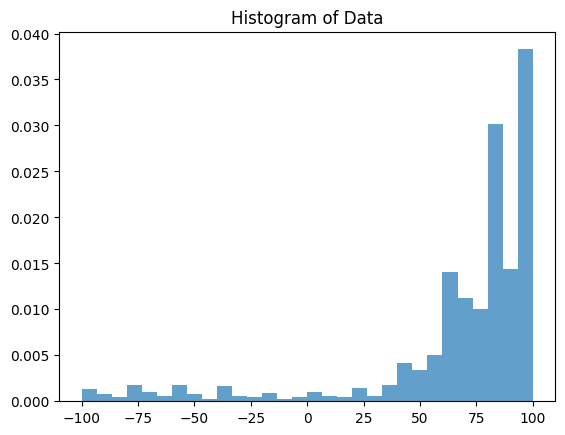

In [13]:
plt.hist(data['Handedness'], bins=30, density=True, alpha=0.7)
plt.title("Histogram of Data")
plt.show()

Plot the distribution of Handedness for left and right-handed subjects

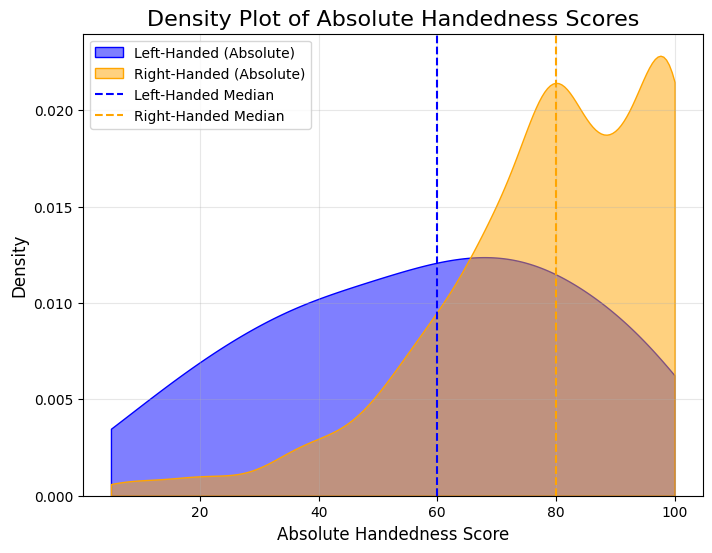

In [14]:
# Take absolute values of Handedness
left_handed_abs = left_handed['Handedness'].abs()
right_handed_abs = right_handed['Handedness'].abs()

plt.figure(figsize=(8, 6))

sns.kdeplot(left_handed_abs, color='blue', label='Left-Handed (Absolute)', fill=True, alpha=0.5, cut=0)
sns.kdeplot(right_handed_abs, color='orange', label='Right-Handed (Absolute)', fill=True, alpha=0.5, cut=0)


# mark medians
plt.axvline(left_handed_abs.median(), color='blue', linestyle='--', label='Left-Handed Median')
plt.axvline(right_handed_abs.median(), color='orange', linestyle='--', label='Right-Handed Median')

# Labels and title
plt.xlabel('Absolute Handedness Score', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.title('Density Plot of Absolute Handedness Scores', fontsize=16)
plt.legend()

plt.grid(alpha=0.3)
plt.show()

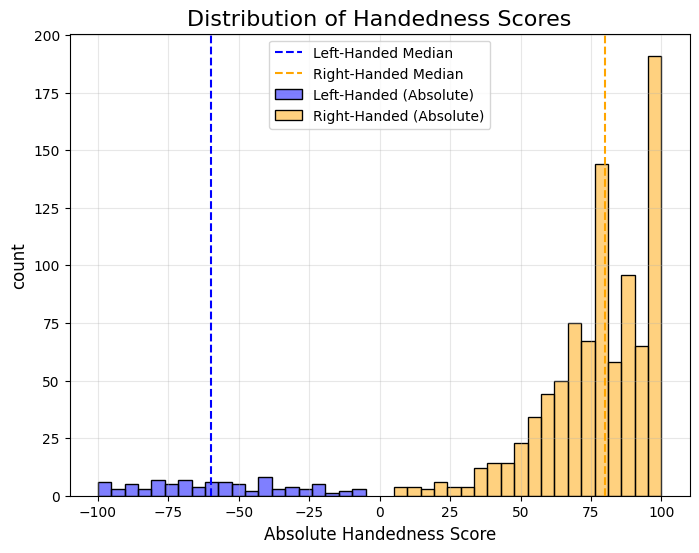

In [15]:
# Take absolute values of Handedness
left_handed_abs = left_handed['Handedness'].abs()
right_handed_abs = right_handed['Handedness'].abs()

plt.figure(figsize=(8, 6))
sns.histplot(left_handed['Handedness'], color='blue', label='Left-Handed (Absolute)', kde=False, bins=20, alpha=0.5)
sns.histplot(right_handed['Handedness'], color='orange', label='Right-Handed (Absolute)', kde=False, bins=20, alpha=0.5)


# mark medians
plt.axvline(left_handed['Handedness'].median(), color='blue', linestyle='--', label='Left-Handed Median')
plt.axvline(right_handed['Handedness'].median(), color='orange', linestyle='--', label='Right-Handed Median')

# Labels and title
plt.xlabel('Absolute Handedness Score', fontsize=12)
plt.ylabel('count', fontsize=12)
plt.title('Distribution of Handedness Scores', fontsize=16)
plt.legend()

plt.grid(alpha=0.3)
plt.show()

In [16]:
left_handed["Handedness"]

7      -75
9      -25
36     -40
46     -20
50     -15
      ... 
948     -5
949    -40
957    -65
964   -100
966    -70
Name: Handedness, Length: 88, dtype: int64

Q-Q Plot (Quantile-Quantile)

Left handed data seemed to be more normally distributed than the right handed. The data is likely normal if the points follow a straight line.

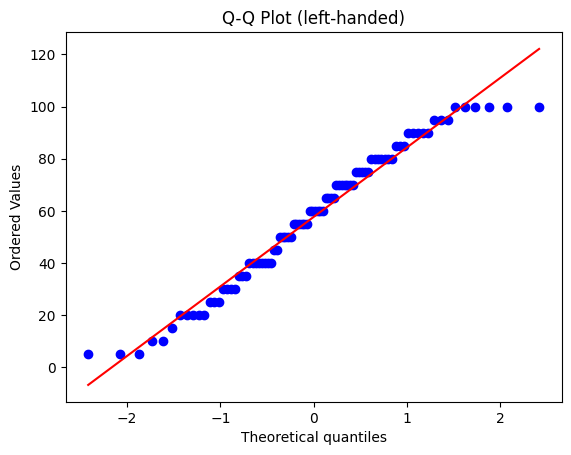

In [17]:
stats.probplot(left_handed_abs, dist="norm", plot=plt)
plt.title("Q-Q Plot (left-handed)")
plt.show()

central part of the distribution seemed normally distributed, but the overall distribution is not normal due to left-skewed tails

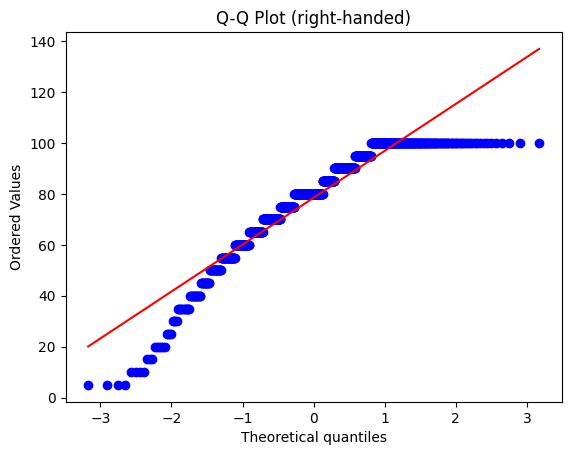

In [18]:
stats.probplot(right_handed_abs, dist="norm", plot=plt)
plt.title("Q-Q Plot (right-handed)")
plt.show()

### Check for Distribution Normality

After normality test, we found out that both of left and right-handed distributions are not normal.

In [19]:
# Test normality for left-handed (absolute values)
stat_left, p_left = shapiro(left_handed_abs)
print(f"Left-Handed: Stat={stat_left}, P-value={p_left}")

# Test normality for right-handed (absolute values)
stat_right, p_right = shapiro(right_handed_abs)
print(f"Right-Handed: Stat={stat_right}, P-value={p_right}")


Left-Handed: Stat=0.9642311848455394, P-value=0.01571961773445103
Right-Handed: Stat=0.8976287608825608, P-value=3.563946911621623e-24


Many parametric hypothesis tests such as t-tests rely on the data's distribution being normal. However as we saw, the distributiosn do not follow a normal distribution, so we can only proceed with non-parametric tests such as the Mann-Whitney U Test for comparing the medians.

### Hypothesis Test On the Medians of the Distributions of Left/Right handed

Mann-Whitney U Test compares medians of distributions and does not require normality of data.

In [20]:
stat, p_value = mannwhitneyu(
    left_handed_abs, 
    right_handed_abs, 
    alternative='two-sided'
)

print("P value:", p_value)


P value: 3.6322011777585514e-13


### Hypothesis Test on CDFs of the Distributions

In [21]:
stat, p_value = ks_2samp(left_handed_abs, right_handed_abs)
print(f"K-S Test Statistic: {stat}, P-value: {p_value}")


K-S Test Statistic: 0.36343700159489634, P-value: 5.492444625226908e-10


Showed significant difference in both the medians and CDFs between the handedness groups.

#### Week 2's Discussion Takeaway

Regression: Keep all data

Classification: try different thresholds to define left and right handedness. After that need to have equal classes by random sampling.

## Thresholding:

Try both -/+25% and -/+40% handedness thresholding on filtering out subjects. 

In [22]:
# Define thresholds
threshold_25 = 25
threshold_40 = 40

# Create classification labels for ±25% threshold
data_25 = data[(data['Handedness'] <= -threshold_25) | (data['Handedness'] >= threshold_25)].copy()
data_25['Class'] = np.where(data_25['Handedness'] >= threshold_25, 1, 0)  # 0: Left-Handed, 1: Right-Handed

# Create classification labels for ±40% threshold
data_40 = data[(data['Handedness'] <= -threshold_40) | (data['Handedness'] >= threshold_40)].copy()
data_40['Class'] = np.where(data_40['Handedness'] >= threshold_40, 1, 0)  # 0: Left-Handed, 1: Right-Handed

data_25['Class'].value_counts(), data_40['Class'].value_counts()


(Class
 1    895
 0     77
 Name: count, dtype: int64,
 Class
 1    875
 0     67
 Name: count, dtype: int64)

In [23]:
# Balance the classes by random sampling
def balance_classes(df, class_column):
    class_0 = df[df[class_column] == 0]
    class_1 = df[df[class_column] == 1]
    
    # Randomly sample the majority class to match the minority class size
    if len(class_0) > len(class_1):
        class_0 = class_0.sample(len(class_1), random_state=42)
    else:
        class_1 = class_1.sample(len(class_0), random_state=42)
    
    return pd.concat([class_0, class_1])

# Apply balancing for ±25% threshold data
balanced_data_25 = balance_classes(data_25, 'Class')

# Apply balancing for ±40% threshold data
balanced_data_40 = balance_classes(data_40, 'Class')

In [24]:
balanced_data_25.shape, balanced_data_40.shape

((154, 784), (134, 784))

In [25]:
balanced_data_25.describe()

,Subject,T1_Count,T2_Count,3T_RS-fMRI_Count,3T_RS-fMRI_PctCompl,3T_tMRI_PctCompl,fMRI_WM_PctCompl,fMRI_Gamb_PctCompl,fMRI_Mot_PctCompl,fMRI_Lang_PctCompl,...,SSAGA_Times_Used_Cocaine,SSAGA_Times_Used_Hallucinogens,SSAGA_Times_Used_Opiates,SSAGA_Times_Used_Sedatives,SSAGA_Times_Used_Stimulants,SSAGA_Mj_Use,SSAGA_Mj_Ab_Dep,SSAGA_Mj_Age_1st_Use,SSAGA_Mj_Times_Used,Class
count,154.000000,154.000000,154.000000,154.0,154.0,154.000000,154.000000,154.0,154.0,154.000000,...,153.000000,153.000000,153.000000,153.000000,153.000000,153.000000,153.000000,80.000000,153.000000,154.000000
mean,374674.805195,1.616883,1.538961,4.0,100.0,99.029221,99.350649,100.0,100.0,98.653896,...,0.339869,0.392157,0.313725,0.156863,0.274510,0.522876,0.098039,2.612500,1.418301,0.500000
std,275780.465121,0.487733,0.500106,0.0,0.0,6.191602,8.058230,0.0,0.0,11.368527,...,1.187453,1.119418,1.126654,0.726542,0.994956,0.501117,0.298344,0.934484,1.741953,0.501631
min,101915.000000,1.000000,1.000000,4.0,100.0,48.600000,0.000000,100.0,100.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,152656.250000,1.000000,1.000000,4.0,100.0,100.000000,100.000000,100.0,100.0,100.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,211017.000000,2.000000,2.000000,4.0,100.0,100.000000,100.000000,100.0,100.0,100.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,3.000000,1.000000,0.500000
75%,569672.500000,2.000000,2.000000,4.0,100.0,100.000000,100.000000,100.0,100.0,100.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,3.000000,3.000000,1.000000
max,992673.000000,2.000000,2.000000,4.0,100.0,100.000000,100.000000,100.0,100.0,100.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,1.000000,1.000000,4.000000,5.000000,1.000000


In [26]:
balanced_data_40.describe()

,Subject,T1_Count,T2_Count,3T_RS-fMRI_Count,3T_RS-fMRI_PctCompl,3T_tMRI_PctCompl,fMRI_WM_PctCompl,fMRI_Gamb_PctCompl,fMRI_Mot_PctCompl,fMRI_Lang_PctCompl,...,SSAGA_Times_Used_Cocaine,SSAGA_Times_Used_Hallucinogens,SSAGA_Times_Used_Opiates,SSAGA_Times_Used_Sedatives,SSAGA_Times_Used_Stimulants,SSAGA_Mj_Use,SSAGA_Mj_Ab_Dep,SSAGA_Mj_Age_1st_Use,SSAGA_Mj_Times_Used,Class
count,134.000000,134.000000,134.000000,134.0,134.0,134.000000,134.000000,134.0,134.0,134.000000,...,133.000000,133.000000,133.000000,133.000000,133.000000,133.000000,133.000000,68.000000,133.000000,134.000000
mean,377990.671642,1.641791,1.567164,4.0,100.0,99.267910,99.253731,100.0,100.0,99.199254,...,0.180451,0.368421,0.203008,0.067669,0.127820,0.511278,0.112782,2.602941,1.451128,0.500000
std,272413.707107,0.481273,0.497328,0.0,0.0,4.978716,8.638684,0.0,0.0,8.656941,...,0.868947,1.055101,0.876973,0.463771,0.644482,0.501763,0.317522,0.994608,1.840068,0.501876
min,101915.000000,1.000000,1.000000,4.0,100.0,48.600000,0.000000,100.0,100.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,157237.000000,1.000000,1.000000,4.0,100.0,100.000000,100.000000,100.0,100.0,100.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,216077.500000,2.000000,2.000000,4.0,100.0,100.000000,100.000000,100.0,100.0,100.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,3.000000,1.000000,0.500000
75%,585096.000000,2.000000,2.000000,4.0,100.0,100.000000,100.000000,100.0,100.0,100.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,3.000000,3.000000,1.000000
max,923755.000000,2.000000,2.000000,4.0,100.0,100.000000,100.000000,100.0,100.0,100.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,1.000000,1.000000,4.000000,5.000000,1.000000


In [27]:
# Handedness statistics
pd.DataFrame([
    balanced_data_25.describe()['Handedness'], 
    balanced_data_40.describe()['Handedness'], 
    data['Handedness'].describe()
], index=['25%', '40%', 'Overall']).T

,25%,40%,Overall
count,154.000000,134.000000,1003.000000
mean,8.409091,5.223881,66.331007
std,74.967759,76.482505,43.608425
min,-100.000000,-100.000000,-100.000000
25%,-65.000000,-70.000000,60.000000
50%,7.500000,2.500000,80.000000
75%,80.000000,80.000000,95.000000
max,100.000000,100.000000,100.000000


### Plot distributions of handedness and other (demographic) features (as brain features TBD for now)

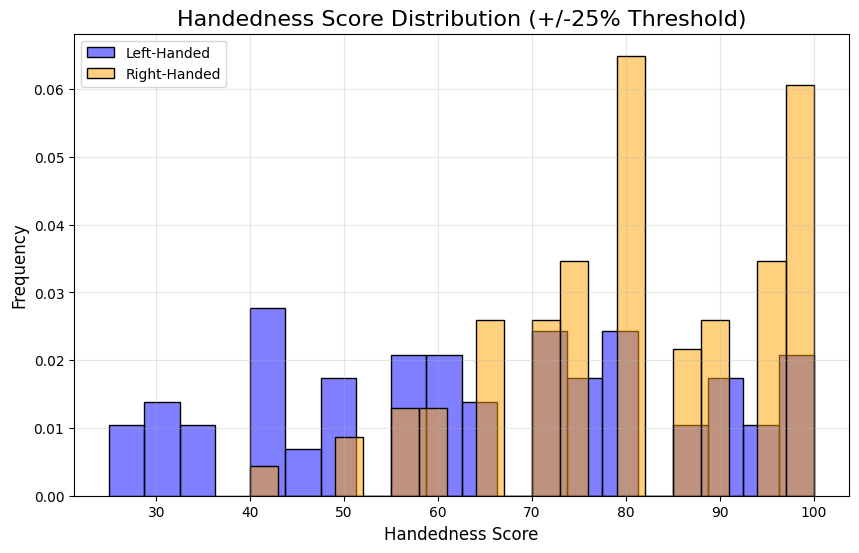

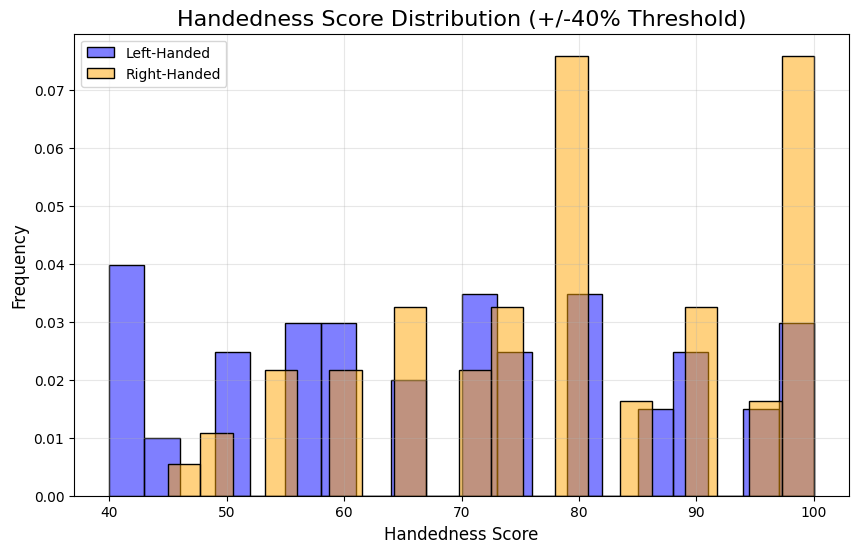

In [28]:
def handedness_distribution(df, title):
    plt.figure(figsize=(10, 6))
    
    # Plot histogram for each group
    sns.histplot(data=df[df['Class'] == 0]['Handedness'].abs(), label='Left-Handed', color='blue', kde=False, bins=20, alpha=0.5, stat='density')
    sns.histplot(data=df[df['Class'] == 1]['Handedness'], label='Right-Handed', color='orange', kde=False, bins=20, alpha=0.5, stat='density')
    
    
    plt.title(title, fontsize=16)
    plt.xlabel('Handedness Score', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


handedness_distribution(balanced_data_25, "Handedness Score Distribution (+/-25% Threshold)")
handedness_distribution(balanced_data_40, "Handedness Score Distribution (+/-40% Threshold)")

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

def continuous_features_w_handedness(df, feature, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots()

    # Plot histogram for each handedness group
    sns.histplot(data=df[df['Class'] == 0][feature], label='Left-Handed', color='blue', kde=False, bins=20, alpha=0.5, ax=ax)
    sns.histplot(data=df[df['Class'] == 1][feature], label='Right-Handed', color='orange', kde=False, bins=20, alpha=0.5, ax=ax)

    ax.set_title(title, fontsize=16)
    ax.set_xlabel(feature, fontsize=12)
    ax.set_ylabel('Frequency', fontsize=12)
    ax.legend()
    ax.grid(alpha=0.3)


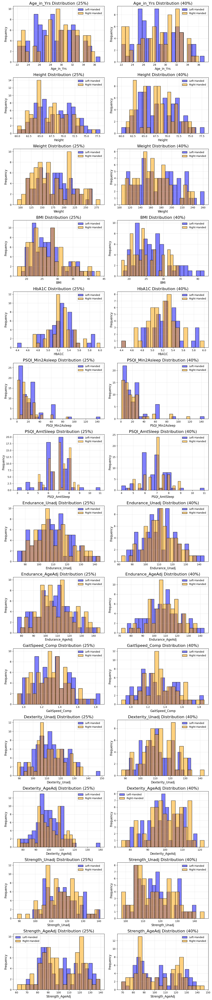

In [30]:
# physical health feature
features = ['Age_in_Yrs', 'Height', 'Weight','BMI', 'HbA1C', 'PSQI_Min2Asleep', 'PSQI_AmtSleep', "Endurance_Unadj", "Endurance_AgeAdj", "GaitSpeed_Comp",
    "Dexterity_Unadj", "Dexterity_AgeAdj", "Strength_Unadj", "Strength_AgeAdj"]

# PSQI_Score: sleep quality; higher score, more acute sleep disturbances. cut off score of 5 to identify possible patients
# HbA1C: # normal: 4.5%-6%, higher than normal indicates risk of diabetes

fig, axes = plt.subplots(len(features), 2, figsize=(12, len(features) * 4))

for i, feature in enumerate(features):
    # Left subplot for balanced_data_25
    continuous_features_w_handedness(balanced_data_25, feature, feature + ' Distribution (25%)', ax=axes[i, 0])
    
    # Right subplot for balanced_data_40
    continuous_features_w_handedness(balanced_data_40, feature, feature + ' Distribution (40%)', ax=axes[i, 1])

plt.tight_layout()
plt.show()

Distribution of categorical variables across handedness groups

In [31]:
def categorical_features_w_handedness(df, feature, title, ax=None):
    counts = df.groupby(['Class', feature]).size().reset_index(name='Count')

    if ax is None:
        fig, ax = plt.subplots()

    sns.barplot(data=counts, x=feature, y='Count', hue='Class', ax=ax)
    ax.set_title(title)
    ax.set_xlabel(feature)
    ax.set_ylabel('Count')

    
    legend_labels = {'0': 'Left-Handed', '1': 'Right-Handed'}
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, [legend_labels[label] for label in labels], title="Handedness", loc='upper right')





In [32]:
import matplotlib.pyplot as plt

features = ['Gender', 'SSAGA_Income', 'SSAGA_Educ', 
            "ER40ANG", "ER40FEAR","ER40HAP", "ER40NOE", "ER40SAD",
            'PSQI_Comp1', 'PSQI_Comp2', 
            'PSQI_Comp3', 'PSQI_Comp4', 'PSQI_Comp5', 'PSQI_Comp6', 'PSQI_Comp7',
            "PSQI_Latency30Min", "PSQI_WakeUp", "PSQI_Bathroom", "PSQI_Breathe",
            "PSQI_Snore", "PSQI_TooCold", "PSQI_TooHot", "PSQI_BadDream",
            "PSQI_Pain", "PSQI_Other", "PSQI_Quality", "PSQI_SleepMeds",
            "PSQI_DayStayAwake", "PSQI_DayEnthusiasm"]

fig, axes = plt.subplots(len(features), 2, figsize=(12, len(features) * 4))

for i, feature in enumerate(features):
    # left subplot: balanced_data_25
    categorical_features_w_handedness(balanced_data_25, feature, feature + ' Distribution (25%)', ax=axes[i, 0])
    
    # right subplot: balanced_data_40
    categorical_features_w_handedness(balanced_data_40, feature, feature + ' Distribution (40%)', ax=axes[i, 1])

plt.tight_layout()
plt.show()


---

### Update - EDA on New Data (Glasser i.e. MMP Parcellation and Cole-Anticevic CA Parcellation)

Load Parcellations

In [33]:
file_path = "parcellations"
file_list = os.listdir(file_path)
mmp = [] # Glasser 2016 which partitions each hemisphere into 180 regions
ca = [] # Cole-Anticevic 2019 which further partitions each hemisphere into ~350 regions
for i in file_list:
    if "mmp" in i:
        mmp_file = np.load(file_path + "/" + i)
        if mmp_file.shape == (3600, 379):
            mmp.append(np.load(file_path + "/" + i))

In [34]:
# one timeseries file example: shape = (n_timepoints, n_regions)
np.load("parcellations/sub-193845_task-rest_parcellation-ca_timeseries.npy").shape

(3600, 718)

In [35]:
open_access_data = pd.read_csv("Behavioral Data/Behavioral_Data.csv")
restricted_data = pd.read_csv("Behavioral Data/RESTRICTED_BEHAVIORAL_DATA.csv")
subject_data = open_access_data.merge(restricted_data, how = 'inner', on = 'Subject')

file_path = "parcellations"
file_list = os.listdir(file_path)
mmp = {}
ca = {}
for filename in file_list:
    subject_id = filename[4:10]

    if subject_id.isdigit():
        subject_id = int(subject_id)

        if "mmp" in filename:
            mmp_file = np.load(file_path + "/" + filename)
            if mmp_file.shape == (3600, 379):
                mmp[subject_id] = mmp_file
        if "ca" in filename:
            ca_file = np.load(file_path + "/" + filename)
            if ca_file.shape == (3600, 718):
                ca[subject_id] = ca_file

mmp_data = pd.DataFrame({
    'Subject': list(mmp.keys()),
    'Brain_Data': list(mmp.values())  # (3600, 379) arrays
})

ca_data = pd.DataFrame({
    'Subject': list(ca.keys()),
    'Brain_Data': list(ca.values())  # (3600, 379) arrays
})

mmp_data = subject_data.merge(mmp_data, on='Subject', how='inner')
ca_data = subject_data.merge(ca_data, on='Subject', how='inner')


In [36]:
mmp_data.head()

,Subject,Release,Acquisition,Gender,Age,3T_Full_MR_Compl,T1_Count,T2_Count,3T_RS-fMRI_Count,3T_RS-fMRI_PctCompl,...,SSAGA_Times_Used_Cocaine,SSAGA_Times_Used_Hallucinogens,SSAGA_Times_Used_Opiates,SSAGA_Times_Used_Sedatives,SSAGA_Times_Used_Stimulants,SSAGA_Mj_Use,SSAGA_Mj_Ab_Dep,SSAGA_Mj_Age_1st_Use,SSAGA_Mj_Times_Used,Brain_Data
0,100610,S900,Q08,M,26-30,True,2,1,4,100.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,"[[2.3968613, 0.33524948, -0.15465337, 1.955118..."
1,102311,S500,Q06,F,26-30,True,1,1,4,100.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,"[[-0.13254918, 0.16243707, 0.300286, 0.6371644..."
2,102816,Q3,Q03,F,26-30,True,1,1,4,100.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,3.0,"[[0.19969857, -0.7308231, -0.46953073, 0.19398..."
3,104416,S900,Q09,F,31-35,True,2,2,4,100.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,3.0,"[[-0.58722323, -2.054348, -2.3991566, -0.60077..."
4,105923,MEG2,Q07,F,31-35,True,2,2,4,100.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,1.0,"[[0.4015313, -0.47590375, -0.058990948, -0.747..."


In [37]:
ca_data.head()

,Subject,Release,Acquisition,Gender,Age,3T_Full_MR_Compl,T1_Count,T2_Count,3T_RS-fMRI_Count,3T_RS-fMRI_PctCompl,...,SSAGA_Times_Used_Cocaine,SSAGA_Times_Used_Hallucinogens,SSAGA_Times_Used_Opiates,SSAGA_Times_Used_Sedatives,SSAGA_Times_Used_Stimulants,SSAGA_Mj_Use,SSAGA_Mj_Ab_Dep,SSAGA_Mj_Age_1st_Use,SSAGA_Mj_Times_Used,Brain_Data
0,100610,S900,Q08,M,26-30,True,2,1,4,100.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,"[[2.3968613, 0.33524948, -0.15465337, 1.955118..."
1,102311,S500,Q06,F,26-30,True,1,1,4,100.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,"[[-0.13254918, 0.16243707, 0.300286, 0.6371644..."
2,102816,Q3,Q03,F,26-30,True,1,1,4,100.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,3.0,"[[0.19969857, -0.7308231, -0.46953073, 0.19398..."
3,104416,S900,Q09,F,31-35,True,2,2,4,100.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,3.0,"[[-0.58722323, -2.054348, -2.3991566, -0.60077..."
4,105923,MEG2,Q07,F,31-35,True,2,2,4,100.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,1.0,"[[0.4015313, -0.47590375, -0.058990948, -0.747..."


In [38]:
mmp_data["Handedness_Cat"] = mmp_data["Handedness"].apply(lambda x: 0 if x < 0 else 1)
ca_data["Handedness_Cat"] = ca_data["Handedness"].apply(lambda x: 0 if x < 0 else 1)
hand_data = mmp_data[["Subject", "Gender", "Race", "Handedness", "Handedness_Cat"]]
hand_data

,Subject,Gender,Race,Handedness,Handedness_Cat
0,100610,M,White,85,1
1,102311,F,White,10,1
2,102816,F,Black or African Am.,100,1
3,104416,F,Asian/Nat. Hawaiian/Othr Pacific Is.,65,1
4,105923,F,White,35,1
...,...,...,...,...,...
167,943862,M,White,95,1
168,958976,M,White,85,1
169,966975,M,White,40,1
170,971160,M,White,80,1


In [39]:
left_handed = hand_data[hand_data['Handedness'] < 0] 
right_handed = hand_data[hand_data['Handedness'] > 0]

# Handedness statistics
pd.DataFrame([
    left_handed.describe()['Handedness'], 
    right_handed.describe()['Handedness'], 
    hand_data['Handedness'].describe()
], index=['Left-Handed', 'Right-Handed', 'Overall']).T

,Left-Handed,Right-Handed,Overall
count,13.000000,159.000000,172.000000
mean,-48.846154,79.622642,69.912791
std,34.104853,19.980585,40.129446
min,-100.000000,10.000000,-100.000000
25%,-75.000000,70.000000,65.000000
50%,-40.000000,85.000000,80.000000
75%,-30.000000,95.000000,95.000000
max,-5.000000,100.000000,100.000000


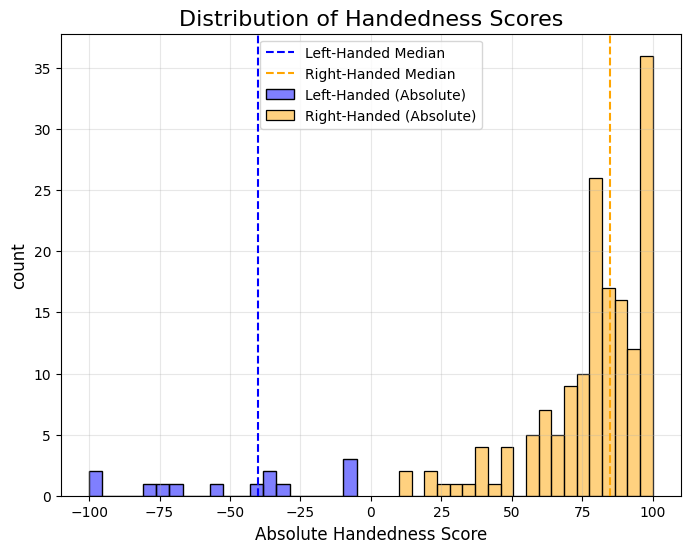

In [40]:
# Take absolute values of Handedness
left_handed_abs = left_handed['Handedness'].abs()
right_handed_abs = right_handed['Handedness'].abs()

plt.figure(figsize=(8, 6))
sns.histplot(left_handed['Handedness'], color='blue', label='Left-Handed (Absolute)', kde=False, bins=20, alpha=0.5)
sns.histplot(right_handed['Handedness'], color='orange', label='Right-Handed (Absolute)', kde=False, bins=20, alpha=0.5)


# mark medians
plt.axvline(left_handed['Handedness'].median(), color='blue', linestyle='--', label='Left-Handed Median')
plt.axvline(right_handed['Handedness'].median(), color='orange', linestyle='--', label='Right-Handed Median')

# Labels and title
plt.xlabel('Absolute Handedness Score', fontsize=12)
plt.ylabel('count', fontsize=12)
plt.title('Distribution of Handedness Scores', fontsize=16)
plt.legend()

plt.grid(alpha=0.3)
plt.show()

In [41]:
mmp_regions = list(hcp.mmp.labels.values())[1:]
len(mmp_regions)

379

In [42]:
mmp_regions[:5]

[np.str_('L_V1'),
 np.str_('L_MST'),
 np.str_('L_V6'),
 np.str_('L_V2'),
 np.str_('L_V3')]

In [43]:
# Separate left and right regions
left_regions_mmp = [region for region in mmp_regions if region.startswith("L_") or "left" in region]
right_regions_mmp = [region for region in mmp_regions if region.startswith("R_") or "right" in region]

print("Left Regions:", left_regions_mmp)
print("Right Regions:", right_regions_mmp)
(len(left_regions_mmp), len(right_regions_mmp))

Left Regions: [np.str_('L_V1'), np.str_('L_MST'), np.str_('L_V6'), np.str_('L_V2'), np.str_('L_V3'), np.str_('L_V4'), np.str_('L_V8'), np.str_('L_4'), np.str_('L_3b'), np.str_('L_FEF'), np.str_('L_PEF'), np.str_('L_55b'), np.str_('L_V3A'), np.str_('L_RSC'), np.str_('L_POS2'), np.str_('L_V7'), np.str_('L_IPS1'), np.str_('L_FFC'), np.str_('L_V3B'), np.str_('L_LO1'), np.str_('L_LO2'), np.str_('L_PIT'), np.str_('L_MT'), np.str_('L_A1'), np.str_('L_PSL'), np.str_('L_SFL'), np.str_('L_PCV'), np.str_('L_STV'), np.str_('L_7Pm'), np.str_('L_7m'), np.str_('L_POS1'), np.str_('L_23d'), np.str_('L_v23ab'), np.str_('L_d23ab'), np.str_('L_31pv'), np.str_('L_5m'), np.str_('L_5mv'), np.str_('L_23c'), np.str_('L_5L'), np.str_('L_24dd'), np.str_('L_24dv'), np.str_('L_7AL'), np.str_('L_SCEF'), np.str_('L_6ma'), np.str_('L_7Am'), np.str_('L_7PL'), np.str_('L_7PC'), np.str_('L_LIPv'), np.str_('L_VIP'), np.str_('L_MIP'), np.str_('L_1'), np.str_('L_2'), np.str_('L_3a'), np.str_('L_6d'), np.str_('L_6mp'), np.s

(189, 189)

In [44]:
hcp.view_parcellation(hcp.mesh.inflated, hcp.mmp)

In [45]:
ca_regions = list(hcp.ca_parcels.labels.values())[1:]
len(ca_regions)

718

In [46]:
ca_regions[:5]

[np.str_('Visual1-04_L-Ctx'),
 np.str_('Visual2-28_L-Ctx'),
 np.str_('Visual2-29_L-Ctx'),
 np.str_('Visual2-30_L-Ctx'),
 np.str_('Visual2-31_L-Ctx')]

In [47]:
# Separate left and right regions
left_regions_ca = [region for region in mmp_regions if region.startswith("L_") or "left" in region]
right_regions_ca = [region for region in mmp_regions if region.startswith("R_") or "right" in region]

print("Left Regions:", left_regions_ca)
print("Right Regions:", right_regions_ca)
(len(left_regions_ca), len(right_regions_ca))

Left Regions: [np.str_('L_V1'), np.str_('L_MST'), np.str_('L_V6'), np.str_('L_V2'), np.str_('L_V3'), np.str_('L_V4'), np.str_('L_V8'), np.str_('L_4'), np.str_('L_3b'), np.str_('L_FEF'), np.str_('L_PEF'), np.str_('L_55b'), np.str_('L_V3A'), np.str_('L_RSC'), np.str_('L_POS2'), np.str_('L_V7'), np.str_('L_IPS1'), np.str_('L_FFC'), np.str_('L_V3B'), np.str_('L_LO1'), np.str_('L_LO2'), np.str_('L_PIT'), np.str_('L_MT'), np.str_('L_A1'), np.str_('L_PSL'), np.str_('L_SFL'), np.str_('L_PCV'), np.str_('L_STV'), np.str_('L_7Pm'), np.str_('L_7m'), np.str_('L_POS1'), np.str_('L_23d'), np.str_('L_v23ab'), np.str_('L_d23ab'), np.str_('L_31pv'), np.str_('L_5m'), np.str_('L_5mv'), np.str_('L_23c'), np.str_('L_5L'), np.str_('L_24dd'), np.str_('L_24dv'), np.str_('L_7AL'), np.str_('L_SCEF'), np.str_('L_6ma'), np.str_('L_7Am'), np.str_('L_7PL'), np.str_('L_7PC'), np.str_('L_LIPv'), np.str_('L_VIP'), np.str_('L_MIP'), np.str_('L_1'), np.str_('L_2'), np.str_('L_3a'), np.str_('L_6d'), np.str_('L_6mp'), np.s

(189, 189)

In [48]:
hcp.view_parcellation(hcp.mesh.inflated, hcp.ca_parcels)

In [49]:
mmp_correlation_matrix_list = []
for i in range(mmp_data.shape[0]):
    person = mmp_data["Brain_Data"][i]
    #get matrix
    person_matrix = np.corrcoef(person.T)
    #append to list
    mmp_correlation_matrix_list.append(person_matrix)
#append to column
mmp_data["correlation_matrix"] = mmp_correlation_matrix_list

In [50]:
ca_correlation_matrix_list = []
for i in range(ca_data.shape[0]):
    person = ca_data["Brain_Data"][i]
    #get matrix
    person_matrix = np.corrcoef(person.T)
    #append to list
    ca_correlation_matrix_list.append(person_matrix)
#append to column
ca_data["correlation_matrix"] = ca_correlation_matrix_list

In [51]:
def feature_row_get(target):
    target_index = mmp_regions.index(target)
    target_row = mmp_data['correlation_matrix'].apply(lambda x: x[target_index])
    
    return target_row

# Function to extract features automatically
def extract_features(region_list, data):
    """
    Extracts the correlation matrix rows for each brain region in region_list.
    
    Parameters:
    - region_list: List of brain region names (e.g., ["L_MT", "L_4", "R_4"])
    - data: DataFrame containing "correlation_matrix"
    
    Returns:
    - DataFrame with extracted features
    """
    # Copy the relevant columns first
    feature_data = data[["Handedness", "Handedness_Cat", "correlation_matrix"]].copy()
    

    # Compute the mean of the entire correlation matrix as a baseline feature
    feature_data["matrix_mean"] = data["correlation_matrix"].apply(lambda x: np.mean(x))

    # Apply feature_row_get() dynamically and store in a dictionary
    for region in region_list:
        feature_data[region] = feature_row_get(region)

    return feature_data


In [52]:
# Extract features for handedness prediction
feature_data = extract_features(mmp_regions, mmp_data)
feature_data

/var/folders/bz/8tkr7qg51_1bcjy3cf4g8fzc0000gn/T/ipykernel_77283/2973537670.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data[region] = feature_row_get(region)
/var/folders/bz/8tkr7qg51_1bcjy3cf4g8fzc0000gn/T/ipykernel_77283/2973537670.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data[region] = feature_row_get(region)
/var/folders/bz/8tkr7qg51_1bcjy3cf4g8fzc0000gn/T/ipykernel_77283/2973537670.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.i

,Handedness,Handedness_Cat,correlation_matrix,matrix_mean,L_V1,L_MST,L_V6,L_V2,L_V3,L_V4,...,diencephalon_right,hippocampus_left,hippocampus_right,pallidum_left,pallidum_right,putamen_left,putamen_right,thalamus_left,thalamus_right,brainStem
0,85,1,"[[1.0, 0.46619928616491757, 0.5387587799680043...",0.175993,"[1.0, 0.46619928616491757, 0.5387587799680043,...","[0.46619928616491757, 0.9999999999999998, 0.44...","[0.5387587799680041, 0.4499977040762726, 1.0, ...","[0.8892868416109532, 0.4980392488505337, 0.669...","[0.869789454122726, 0.496984255970309, 0.53679...","[0.8147514719478919, 0.5400295037559002, 0.457...",...,"[0.35503242298914717, 0.2099338262698585, 0.20...","[0.3707425600137387, 0.23266761769771335, 0.30...","[0.3645208696856842, 0.22235976940137983, 0.35...","[0.12714982306826506, 0.06748345035761996, 0.0...","[0.13308024868626978, 0.1077981888115347, 0.05...","[0.3100933161756262, 0.24881346059399678, 0.17...","[0.3265738264531844, 0.2825369441278569, 0.198...","[0.5864892059883535, 0.3648707037374211, 0.371...","[0.5582765289662259, 0.35101745169885495, 0.38...","[0.5856313541418544, 0.363891982671451, 0.3986..."
1,10,1,"[[1.0, 0.4145113094959292, 0.342818966658749, ...",0.186351,"[1.0, 0.4145113094959292, 0.342818966658749, 0...","[0.4145113094959292, 0.9999999999999998, 0.704...","[0.34281896665874906, 0.7047527617097026, 1.0,...","[0.6488255962501398, 0.724840686113523, 0.7825...","[0.6113703275460517, 0.7378185708491541, 0.708...","[0.5720238401844869, 0.7336501426408212, 0.666...",...,"[0.4709289268511789, 0.10776035647735094, 0.08...","[0.2879182701749582, 0.16885750108802908, 0.17...","[0.2866675631876025, 0.21960607335957785, 0.23...","[0.18765225174159839, 0.04342396605090036, 0.0...","[0.16063836306979595, 0.013452149788054339, 0....","[0.2989966594350158, 0.02963297790273026, -0.1...","[0.28908567047301875, -0.08507595951425063, -0...","[0.5825102955540145, 0.007198172227728307, -0....","[0.5496595299756764, -0.020745895635067197, -0...","[0.5698083573040247, 0.34655284202675646, 0.29..."
2,100,1,"[[0.9999999999999998, 0.2989986241314227, 0.52...",0.258471,"[0.9999999999999998, 0.2989986241314227, 0.524...","[0.2989986241314227, 1.0, 0.5510809248076038, ...","[0.5246834631760836, 0.5510809248076038, 1.0, ...","[0.8090802391751148, 0.5339015630405952, 0.784...","[0.7751268075554022, 0.5292534475702055, 0.692...","[0.7091369855773447, 0.49772635124286263, 0.55...",...,"[0.3763481696712148, 0.17556581932283635, 0.15...","[0.2900142576369598, 0.44922905563451815, 0.52...","[0.3312662521181269, 0.4720732520795355, 0.533...","[0.18502032428149845, 0.0435007869405236, 0.09...","[0.2555694990185411, 0.08001469690627191, 0.08...","[0.3608501034288935, 0.08720571776315682, 0.11...","[0.3666126674932228, 0.04576551554754129, 0.10...","[0.5161074827653371, 0.17155229937390812, 0.23...","[0.5746687762566225, 0.13914864892984888, 0.25...","[0.5656910983821719, 0.3687751577105434, 0.502..."
3,65,1,"[[0.9999999999999998, 0.5081583697070787, 0.59...",0.211318,"[0.9999999999999998, 0.5081583697070787, 0.596...","[0.5081583697070786, 0.9999999999999998, 0.613...","[0.5960509332794675, 0.6139467613552139, 1.0, ...","[0.7814169550548589, 0.6980576885742854, 0.783...","[0.7177598637023298, 0.6730018479886771, 0.592...","[0.5931971888110517, 0.624906692133618, 0.3732...",...,"[0.20001582138770246, -0.008832310693729608, -...","[0.14761707593432147, 0.18072463522352433, 0.1...","[0.1374744519481748, 0.2004803394442056, 0.185...","[0.10619929568834638, 0.05873361949050927, 0.0...","[0.13088559190339152, 0.12902723145355785, 0.1...","[0.2148320182060796, 0.008706104476269587, 0.0...","[0.22165574154445203, 0.032556552822297496, 0....","[0.521820363701444, 0.39598278258570213, 0.369...","[0.4775837813669714, 0.361452635371305, 0.3442...","[0.506131300140526, 0.48203909591560734, 0.494..."
4,35,1,"[[1.0, 0.5963831451011642, 0.6588621195832001,...",0.327927,"[1.0, 0.5963831451011642, 0.6588621195832001, ...","[0.5963831451011642,

### Statistical Analysis of Brain Symmetry (In general)

1. Compute interhemispheric correlations for homologous brain regions (left vs. right). For each left-right region pair, we used the Pearson correlation coefficient.

e.g. the correlation between "L-A1" and "R-A1"

       Correlation
count   189.000000
mean      0.862477
std       0.118418
min       0.370316
25%       0.807534
50%       0.904409
75%       0.948065
max       0.992144


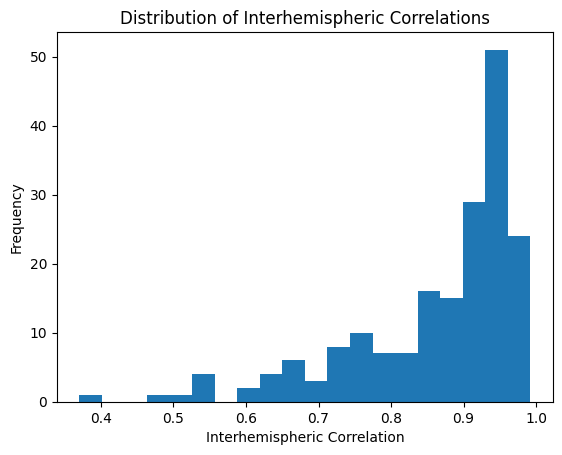

In [53]:
# Compute correlations between homologous left and right regions
corrs = []

for left, right in zip(left_regions_mmp, right_regions_mmp):
    left_values = np.array(feature_data[left].tolist()).astype(float)  # Convert object dtype to float
    right_values = np.array(feature_data[right].tolist()).astype(float)

    if left_values.ndim > 1:  # Flatten if multi-dimensional
        left_values = left_values.flatten()
    if right_values.ndim > 1:
        right_values = right_values.flatten()

    corr = np.corrcoef(left_values, right_values)[0, 1]  # Compute correlation
    corrs.append(corr)

# visualizing the correlations
symmetry_df = pd.DataFrame({"Region": left_regions_mmp, "Correlation": corrs})

print(symmetry_df.describe())

plt.hist(corrs, bins=20)
plt.xlabel("Interhemispheric Correlation")
plt.ylabel("Frequency")
plt.title("Distribution of Interhemispheric Correlations")
plt.show()

The median the correlations are high (0.9), meaning that brain activity is highly symmetric in resting state. Rsting-state fMRI data reflects strong interhemispheric symmetry instead of potential laterialization.

2. Compute the correlations for edges within each hemisphere, e.g. correlation between "R-A1" and "R-A2"

For MMP Parcellation

           Correlation                                                    \
                 count      mean       std       min       25%       50%   
Hemisphere                                                                 
Left           17766.0  0.705780  0.128784  0.238188  0.650310  0.737519   
Right          17766.0  0.706059  0.120658 -0.006229  0.654158  0.727253   

                                
                 75%       max  
Hemisphere                      
Left        0.793518  0.888648  
Right       0.797530  0.878956  


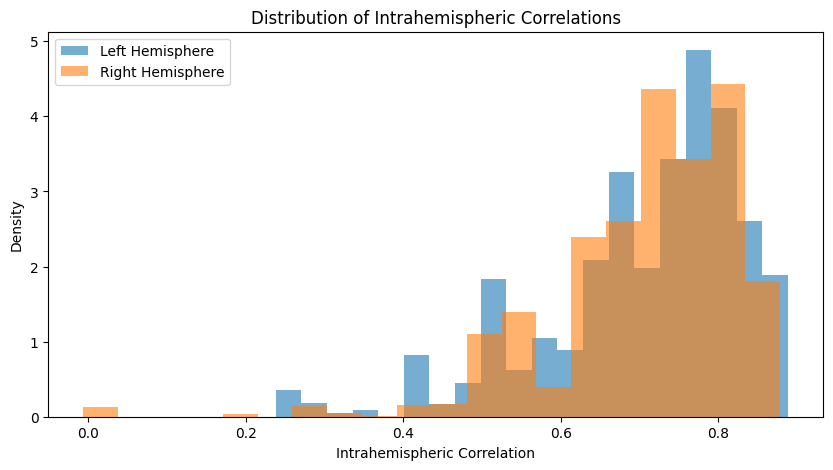

In [54]:
left_hemisphere_regions = [region for region in mmp_regions if region.startswith("L_") or "left" in region]
right_hemisphere_regions = [region for region in mmp_regions if region.startswith("R_") or "right" in region]

# Compute correlations for left hemisphere
left_intra_corrs = []
for i, region1 in enumerate(left_hemisphere_regions):
    for j, region2 in enumerate(left_hemisphere_regions):
        if i < j:
            values1 = np.array(feature_data[region1].tolist()).astype(float)
            values2 = np.array(feature_data[region2].tolist()).astype(float)
            corr = np.corrcoef(values1, values2)[0, 1]
            left_intra_corrs.append(corr)

# Compute correlations for right hemisphere
right_intra_corrs = []
for i, region1 in enumerate(right_hemisphere_regions):
    for j, region2 in enumerate(right_hemisphere_regions):
        if i < j:
            values1 = np.array(feature_data[region1].tolist()).astype(float)
            values2 = np.array(feature_data[region2].tolist()).astype(float)
            corr = np.corrcoef(values1, values2)[0, 1]
            right_intra_corrs.append(corr)

# Convert results to DataFrame for summary statistics
left_corr_df = pd.DataFrame({"Correlation": left_intra_corrs, "Hemisphere": "Left"})
right_corr_df = pd.DataFrame({"Correlation": right_intra_corrs, "Hemisphere": "Right"})
intrahemispheric_df = pd.concat([left_corr_df, right_corr_df])

# Print summary statistics
print(intrahemispheric_df.groupby("Hemisphere").describe())

plt.figure(figsize=(10, 5))
plt.hist(left_intra_corrs, bins=20, alpha=0.6, label="Left Hemisphere", density=True)
plt.hist(right_intra_corrs, bins=20, alpha=0.6, label="Right Hemisphere", density=True)
plt.xlabel("Intrahemispheric Correlation")
plt.ylabel("Density")
plt.title("Distribution of Intrahemispheric Correlations")
plt.legend()

For CA Parcellation

In [55]:
ca_regions

[np.str_('Visual1-04_L-Ctx'),
 np.str_('Visual2-28_L-Ctx'),
 np.str_('Visual2-29_L-Ctx'),
 np.str_('Visual2-30_L-Ctx'),
 np.str_('Visual2-31_L-Ctx'),
 np.str_('Visual2-32_L-Ctx'),
 np.str_('Visual2-33_L-Ctx'),
 np.str_('Somatomotor-21_L-Ctx'),
 np.str_('Somatomotor-22_L-Ctx'),
 np.str_('Cingulo-Opercular-30_L-Ctx'),
 np.str_('Dorsal-Attention-12_L-Ctx'),
 np.str_('Language-10_L-Ctx'),
 np.str_('Visual2-34_L-Ctx'),
 np.str_('Frontoparietal-29_L-Ctx'),
 np.str_('Frontoparietal-30_L-Ctx'),
 np.str_('Visual2-35_L-Ctx'),
 np.str_('Visual2-36_L-Ctx'),
 np.str_('Visual2-37_L-Ctx'),
 np.str_('Visual2-38_L-Ctx'),
 np.str_('Visual2-39_L-Ctx'),
 np.str_('Visual2-40_L-Ctx'),
 np.str_('Visual2-41_L-Ctx'),
 np.str_('Visual2-42_L-Ctx'),
 np.str_('Auditory-08_L-Ctx'),
 np.str_('Language-11_L-Ctx'),
 np.str_('Language-12_L-Ctx'),
 np.str_('Posterior-Multimodal-05_L-Ctx'),
 np.str_('Language-13_L-Ctx'),
 np.str_('Frontoparietal-31_L-Ctx'),
 np.str_('Default-38_L-Ctx'),
 np.str_('Default-39_L-Ctx'),
 np.

3. correlations all pairs of left and right regions correlations

Instead of only matching "L_A1" with "R_A1", this includes "L_A1" with "R_A2", "R_A3", ..., "R_PHT".

count    35721.000000
mean         0.691156
std          0.143870
min         -0.046312
25%          0.638780
50%          0.731549
75%          0.786193
max          0.888648
Name: Correlation, dtype: float64


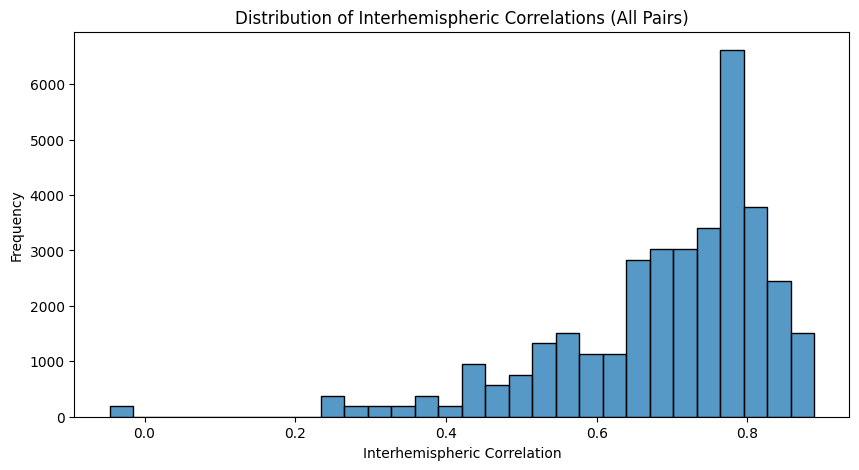

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# List of left and right hemisphere regions
left_hemisphere_regions = [region for region in mmp_regions if region.startswith("L_") or 'left' in region]
right_hemisphere_regions = [region for region in mmp_regions if region.startswith("R_") or 'right' in region]

# Store correlations
interhemispheric_corrs = []

# Compute correlations for all left-right region pairs
for left in left_hemisphere_regions:
    for right in right_hemisphere_regions:
        left_values = np.array(feature_data[left].tolist()).astype(float)
        right_values = np.array(feature_data[right].tolist()).astype(float)

        corr = np.corrcoef(left_values, right_values)[0, 1]  # Compute correlation
        interhemispheric_corrs.append({"Left Region": left, "Right Region": right, "Correlation": corr})

# Convert to DataFrame
interhemispheric_df = pd.DataFrame(interhemispheric_corrs)

# Print summary statistics
print(interhemispheric_df["Correlation"].describe())


# Plot histogram to visualize correlation distribution
plt.figure(figsize=(10, 5))
sns.histplot(interhemispheric_df["Correlation"], bins=30)
plt.xlabel("Interhemispheric Correlation")
plt.ylabel("Frequency")
plt.title("Distribution of Interhemispheric Correlations (All Pairs)")
plt.show()

# # Heatmap to show pairwise correlations
# pivot_df = interhemispheric_df.pivot(index="Left Region", columns="Right Region", values="Correlation")

# plt.figure(figsize=(15, 12))
# sns.heatmap(pivot_df, cmap="coolwarm", center=0, annot=False, linewidths=0.5)
# plt.title("Interhemispheric Correlation Heatmap")
# plt.show()


### Statistical Analysis of Brain Symmetry (By Left- and Right-Handed Groups Separately)

Compare the distributions of brain activites for left- and right-handed individuals.
Perform t-test to check if there's a significant difference.

For left- and right-handed individuals, did the following for each pair of corresponding brain regions (e.g., "L_V1" & "R_V1", "L_4" & "R_4"):
* Extracts the values for that region in left-handed individuals.
* Computes the Pearson correlation coefficient between the left and corresponding right regions.
* stores the correlation values in 

In [57]:
# Separate data by handedness
left_handed = feature_data[feature_data["Handedness_Cat"] == 0]  # Adjust category accordingly
right_handed = feature_data[feature_data["Handedness_Cat"] == 1]

# Compute group-wise correlations

left_corrs = [
    np.corrcoef(np.array(left_handed[left].tolist(), dtype=float), 
                np.array(left_handed[right].tolist(), dtype=float))[0, 1]
    for left, right in zip(left_regions_mmp, right_regions_mmp)
]
right_corrs = [
    np.corrcoef(np.array(right_handed[left].tolist(), dtype=float), 
                np.array(right_handed[right].tolist(), dtype=float))[0, 1]
    for left, right in zip(left_regions_mmp, right_regions_mmp)
]

# Perform t-test
t_stat, p_value = ttest_ind(left_corrs, right_corrs)
print("T-statistic: ", t_stat, ', P-value: ', p_value)

# Perform Mann-Whitney U test
u_stat, p_value_u = mannwhitneyu(left_corrs, right_corrs, alternative="two-sided")
print("U-Stat: ", u_stat, ', P_value', p_value_u)


T-statistic:  1.6037147386688697 , P-value:  0.10961657304701984
U-Stat:  19478.0 , P_value 0.1279172606199262


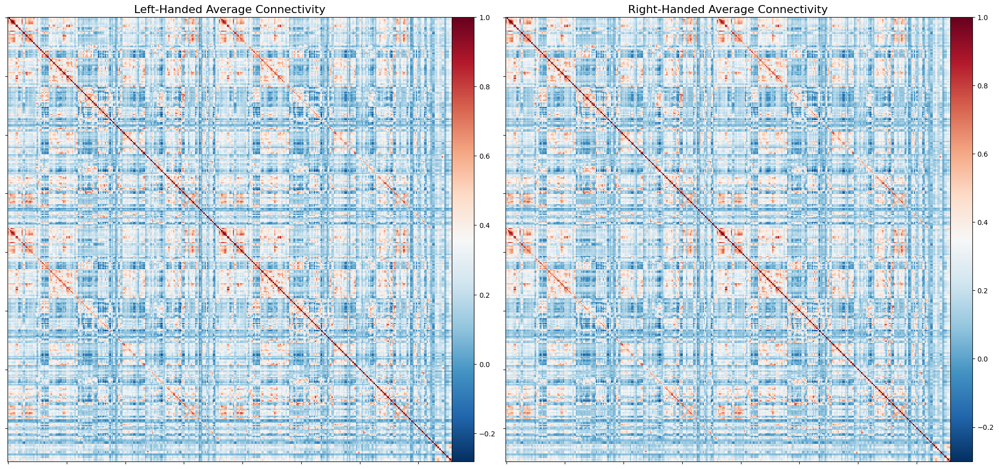

In [58]:
# Compute and plot the average correlation matrices for every pair of regions for left- and right-handers
left_avg_corr = np.mean(np.array(left_handed["correlation_matrix"].tolist()), axis=0) # shape: (379, 379)
right_avg_corr = np.mean(np.array(right_handed["correlation_matrix"].tolist()), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(20, 10))
plotting.plot_matrix(left_avg_corr, axes=axes[0], title="Left-Handed Average Connectivity")
plotting.plot_matrix(right_avg_corr, axes=axes[1], title="Right-Handed Average Connectivity")

plt.show()

### Statistical Analysis on Region-to-Handedness Correlations

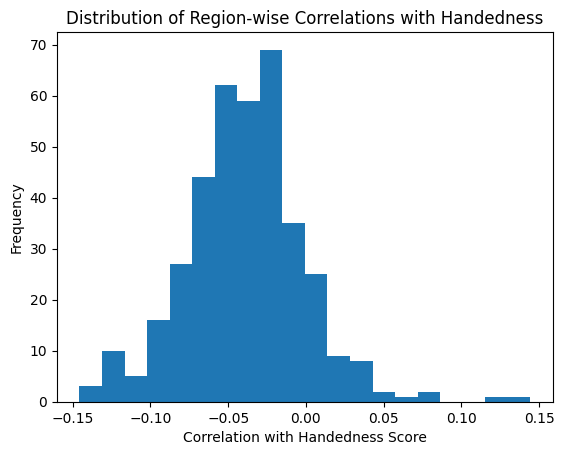

              Region  Correlation
288            R_Pir     0.144309
175           L_TE1m     0.116918
110           L_AAIC     0.083266
290           R_AAIC     0.081637
365  cerebellum_left     0.058738
203            R_PSL     0.051261
343            R_s32     0.044803
83          L_a9-46v     0.038398
159           L_31pd     0.032610
199            R_LO2     0.031797
       Region  Correlation
250     R_10d    -0.119986
170     L_TGv    -0.120179
81   L_p9-46v    -0.121491
168    L_p10p    -0.124604
261  R_p9-46v    -0.126149
116      L_EC    -0.126982
269     R_11l    -0.127394
90      L_13l    -0.131537
351   R_MBelt    -0.131855
301    R_STGa    -0.145630


In [59]:
# Compute mean connectivity per region across all its connections
region_means = np.mean(np.array(feature_data["correlation_matrix"].tolist()), axis=1)  # (172, 379)

# Compute correlations with handedness score
corrs_with_handedness = [spearmanr(region_means[:, i], feature_data["Handedness"])[0] for i in range(region_means.shape[1])]

# Convert to DataFrame for analysis
region_corr_df = pd.DataFrame({"Region": mmp_regions[1:], "Correlation": corrs_with_handedness[1:]})

# Plot the distribution of correlations
plt.hist(corrs_with_handedness, bins=20)
plt.xlabel("Correlation with Handedness Score")
plt.ylabel("Frequency")
plt.title("Distribution of Region-wise Correlations with Handedness")
plt.show()

# Show top correlated regions
region_corr_df = region_corr_df.sort_values(by="Correlation", ascending=False)
print(region_corr_df.head(10))  # Top 10 strongest positive correlations
print(region_corr_df.tail(10))  # Top 10 strongest negative correlations
